## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [138]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nathan Brence

**Date:** 10/19/2026

Text(0, 0.5, 'Frequency')

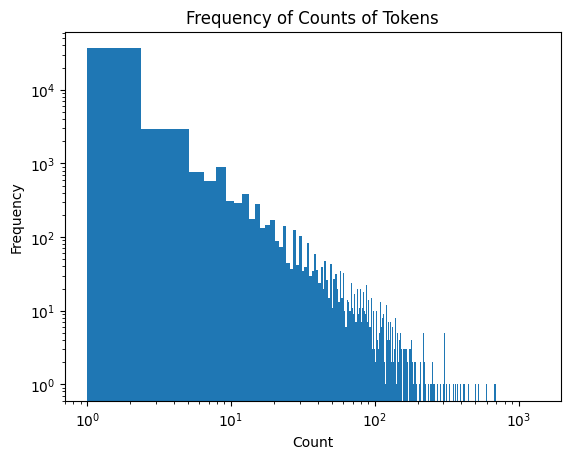

In [139]:
#Question 1
from matplotlib import pyplot as plt
import seaborn as sns

token, count = zip(*token_freq)
token, count = list(token), list(count)

plt.hist(count, bins=1000)
plt.xscale("log")
plt.yscale("log")

plt.title("Frequency of Counts of Tokens")
plt.xlabel("Count")
plt.ylabel("Frequency")

According to the histogram, a large majority of the tokens appear less than 10 times in the dataset, with the tallest bin indicating that the most common frequency is one. Given the log scale on both axes and the downward of the histogram, it's evident that the frequency of token counts are exponentially decreasing, indicating that tokens with larger frequencies are much less common than those with small frequencies.

In [140]:
#Question 2
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

phish = pd.read_parquet("data/Phishing_clean.parquet")

X_phish = phish.loc[:, "new":"italian"] 
y_phish = phish["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X_phish, y_phish, test_size=0.2, random_state=1)

train_model = LinearRegression().fit(X_train, y_train)
test_model = LinearRegression().fit(X_test, y_test)

train_r2 = train_model.score(X_train, y_train)
test_r2 = test_model.score(X_test, y_test)

print(f"Training Model R-Squared: {train_r2:.3f}\nTest Model R-Squared: {test_r2:.3f}")

Training Model R-Squared: 0.769
Test Model R-Squared: 0.902


In [141]:
train_coefs = pd.DataFrame({
    "Variables" : X_phish.columns,
    "Coefficients" : abs(train_model.coef_)
})

test_coefs = pd.DataFrame({
    "Variables" : X_phish.columns,
    "Coefficients" : abs(test_model.coef_)
})

print("Most Influential Training Coefficients")
display(train_coefs.sort_values(by="Coefficients", ascending=False).head(5))
print("Most Influential Test Coefficients")
display(test_coefs.sort_values(by="Coefficients", ascending=False).head(5))

Most Influential Training Coefficients


,Variables,Coefficients
1504,background-image:,1.137598
906,aging,1.043082
740,localized,0.777854
1406,"helvetica,",0.660271
2182,reversing,0.580435


Most Influential Test Coefficients


,Variables,Coefficients
1887,"company,",1.563345
2147,audio,1.552024
1536,express,1.412673
1949,nesa,1.395513
2367,years!,1.303483


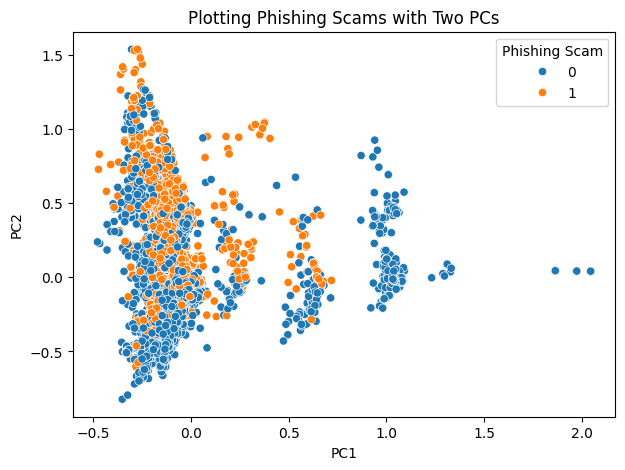

In [142]:
#Question 3
from sklearn.decomposition import PCA

pca_phish = PCA(n_components=2).fit(X_phish)
X_pca = pca_phish.transform(X_phish)

fig, ax = plt.subplots(figsize=(7, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_phish)
ax.set_title("Plotting Phishing Scams with Two PCs")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Phishing Scam")

According to the above plot, the vast majority of scam emails have a low value for the first principal component, as every datapoint with a PC1 score higher than ~0.8 is not asssociated with phishing. Conversely, the second principal component doesn't reveal any major patterns, with both types of emails present across the range of PC2

In [143]:
#Question 4

X_train, X_test, y_train, y_test = train_test_split(X_phish, y_phish, test_size=0.2, random_state=1)

pca_phish = PCA(n_components=2610).fit(X_train)
X_train_pca = pca_phish.transform(X_train)
X_test_pca = pca_phish.transform(X_test)

train_model = LinearRegression().fit(X_train_pca, y_train)
test_model = LinearRegression().fit(X_test_pca, y_test)

train_r2 = train_model.score(X_train_pca, y_train)
test_r2 = test_model.score(X_test_pca, y_test)

print(f"Training Model R-Squared: {train_r2:.3f}\nTest Model R-Squared: {test_r2:.3f}")

Training Model R-Squared: 0.768
Test Model R-Squared: 0.902


According to the above R-Squared values, which are identical to the training and test models from the earlier linear regression, the PCA model doesn't appear to perform any better than regular linear regression. This is likely due to the high number of components used for PCA, which is so close to the number of tokens in the dataset that barely any variation in the data is being reduced. 

Question 5: The advantage of using principal components on high-dimensionality data is to reduce the variation in the dataset by identifying linear combinations between dimensions (Principal Components), which increases predictive accuracy on average. Additionally, it allows high-dimensionality data to be visualized by reducing the dataset to two principal components and plotting each datapoint in accordance with them, revealing patterns in the data that would otherwise be impossible to find.  

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** c8f47e13c817645a19239475e08b21fd766c587d
- **AI tool and model used:** Claude

### *Prompts used

For each of these questions, give a series of suggestions to improve the given answers. Make sure that the suggestions are relevant to the written questions. Give a numbered list of the suggestions at the end of the prompt

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?
**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of y on the one-hot-encoded emails. What is the R2 on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 
**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?
**Q4.**

Run a linear regression of y on the first 2,610 principal components of X. What is the R2 on the training and test sets?
How does this performance compare to the linear regression?
**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Answers: 
#Question 1
from matplotlib import pyplot as plt
import seaborn as sns


token, count = zip(*token_freq)
token, count = list(token), list(count)


plt.hist(count, bins=1000)
plt.xscale("log")
plt.yscale("log")


plt.title("Frequency of Counts of Tokens")
plt.xlabel("Count")
plt.ylabel("Frequency")


According to the histogram, a large majority of the tokens appear less than 10 times in the dataset, with the tallest bin indicating that the most common frequency is one. Given the log scale on both axes and the downward of the histogram, it's evident that the frequency of token counts are exponentially decreasing, indicating that tokens with larger frequencies are much less common than those with small frequencies.


#Question 2
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score


phish = pd.read_parquet("data/Phishing_clean.parquet")


X_phish = phish.loc[:, "new":"italian"]
y_phish = phish["Email Type"]


X_train, X_test, y_train, y_test = train_test_split(X_phish, y_phish, test_size=0.2, random_state=1)


train_model = LinearRegression().fit(X_train, y_train)
test_model = LinearRegression().fit(X_test, y_test)


train_r2 = train_model.score(X_train, y_train)
test_r2 = test_model.score(X_test, y_test)


print(f"Training Model R-Squared: {train_r2:.3f}\nTest Model R-Squared: {test_r2:.3f}")


train_coefs = pd.DataFrame({
    "Variables" : X_phish.columns,
    "Coefficients" : abs(train_model.coef_)
})


test_coefs = pd.DataFrame({
    "Variables" : X_phish.columns,
    "Coefficients" : abs(test_model.coef_)
})


print("Most Influential Training Coefficients")
display(train_coefs.sort_values(by="Coefficients", ascending=False).head(5))
print("Most Influential Test Coefficients")
display(test_coefs.sort_values(by="Coefficients", ascending=False).head(5))


#Question 3
from sklearn.decomposition import PCA


pca_phish = PCA(n_components=2).fit(X_phish)
X_pca = pca_phish.transform(X_phish)


fig, ax = plt.subplots(figsize=(7, 5))


sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_phish)
ax.set_title("Plotting Phishing Scams with Two PCs")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Phishing Scam")


According to the above plot, the vast majority of scam emails have a low value for the first principal component, as every datapoint with a PC1 score higher than ~0.8 is not asssociated with phishing. Conversely, the second principal component doesn't reveal any major patterns, with both types of emails present across the range of PC2


#Question 4


X_train, X_test, y_train, y_test = train_test_split(X_phish, y_phish, test_size=0.2, random_state=1)


pca_phish = PCA(n_components=2610).fit(X_train)
X_train_pca = pca_phish.transform(X_train)
X_test_pca = pca_phish.transform(X_test)


train_model = LinearRegression().fit(X_train_pca, y_train)
test_model = LinearRegression().fit(X_test_pca, y_test)


train_r2 = train_model.score(X_train_pca, y_train)
test_r2 = test_model.score(X_test_pca, y_test)


print(f"Training Model R-Squared: {train_r2:.3f}\nTest Model R-Squared: {test_r2:.3f}")


According to the above R-Squared values, which are identical to the training and test models from the earlier linear regression, the PCA model doesn't appear to perform any better than regular linear regression. This is likely due to the high number of components used for PCA, which is so close to the number of tokens in the dataset that barely any variation in the data is being reduced.


Question 5: The advantage of using principal components on high-dimensionality data is to reduce the variation in the dataset by identifying linear combinations between dimensions (Principal Components), which increases predictive accuracy on average. Additionally, it allows high-dimensionality data to be visualized by reducing the dataset to two principal components and plotting each datapoint in accordance with them, revealing patterns in the data that would otherwise be impossible to find.

### *AI-proposed changes


1. Q2/Q4: score on the test set, don’t refit on it. test_model is fit on X_test, so its R² isn’t a real test score. Use train_model.score(X_test, y_test) (and X_test_pca in Q4).
2. Q2: take coefficients from the training model only. The “test coefficients” table comes from a model trained on test data, so drop it.
3. Q2: keep coefficient signs and interpret them. abs() hides whether a word points toward or away from phishing. Show signed values, state your actual R² numbers, and say what the top words suggest.
4. Q1: use log-spaced bins and fix the description. Use np.logspace bins, or a rank-frequency plot. A straight line on log-log axes means a power law (Zipf’s law), not “exponential decay.”
5. Q3: quantify the plot. Report explained_variance_ratio_ for the two PCs, reduce overplotting with alpha, and back up the “PC1 > 0.8” claim with a number.
6. Q4: compare with real numbers. The R² values should be close to Q2, not identical, since about 100 components were dropped. Add cumulative explained variance, and try fewer components (e.g., 50 to 500) to see if PCA helps.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | This was an oversight on my end when I performed linear regression in phase 1. Not only is the description of my mistake accurate, but validation in a copy of this notebook demonstrates that the test R-Squared is different from the phase 1 version when the above change is applied. |
| 2 | **Accept** / modify / reject | In relation to the previous suggestion, this recommendation is also due to a model trained on test data being nonsensical. Because of this, it only makes sense for one set of coefficients to be present since only one model (the training model) will exist. |
| 3 | Accept / modify / **reject** | The question this recommendation refers to specifically asks for the coefficients to be given in their absolute value. This suggestion can thus be rejected |
| 4 | Accept / modify / **reject** | Not only does the critique regarding the description not make sens as it adequately describes the distribution of tokens, but the measures the suggestions recommends are far outside the bounds of what we learned in class and aren't necessary to increase the histogram's interpretability. Hence, this point can be rejected. |
| 5 | Accept / modify / **reject** | Much of the points in this suggestion are superfluous and aren't necessary to provide an adequate answer to the problem they refer to. Additionally, the 0.8 figure is an estimate (as given by the tilde sign next to it in the phase 1 solution) and isn't meant to be exact, but rather a rough estimate of where phishing scams stop appearing in terms of PC1. |
| 6 | Accept / modify / **reject** | Since the R-squared figures from Question 2 are clearly present in the notebook, the comparison point in this suggestion doesn't make sense. Also, most of the subsequent recommendations are outside the bounds of what Question 4 is asking. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Text(0, 0.5, 'Frequency')

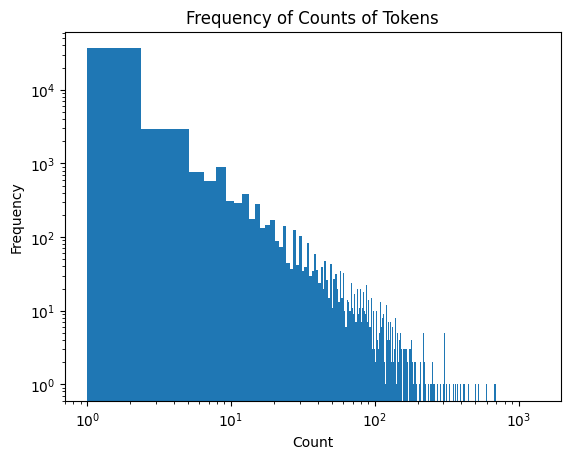

In [144]:
#Question 1
from matplotlib import pyplot as plt
import seaborn as sns

token, count = zip(*token_freq)
token, count = list(token), list(count)

plt.hist(count, bins=1000)
plt.xscale("log")
plt.yscale("log")

plt.title("Frequency of Counts of Tokens")
plt.xlabel("Count")
plt.ylabel("Frequency")

According to the histogram, a large majority of the tokens appear less than 10 times in the dataset, with the tallest bin indicating that the most common frequency is one. Given the log scale on both axes and the downward of the histogram, it's evident that the frequency of token counts are exponentially decreasing, indicating that tokens with larger frequencies are much less common than those with small frequencies.

In [145]:
#Question 2
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

phish = pd.read_parquet("data/Phishing_clean.parquet")

X_phish = phish.loc[:, "new":"italian"] 
y_phish = phish["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X_phish, y_phish, test_size=0.2, random_state=1)

model = LinearRegression().fit(X_train, y_train)

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print(f"Training Model R-Squared: {train_r2:.3f}\nTest Model R-Squared: {test_r2:.3f}")

Training Model R-Squared: 0.769
Test Model R-Squared: 0.652


In [146]:
coefs = pd.DataFrame({
    "Variables" : X_phish.columns,
    "Coefficients" : abs(model.coef_)
})

print("Most Influential Coefficients")
display(coefs.sort_values(by="Coefficients", ascending=False).head(5))

Most Influential Coefficients


,Variables,Coefficients
1504,background-image:,1.137598
906,aging,1.043082
740,localized,0.777854
1406,"helvetica,",0.660271
2182,reversing,0.580435


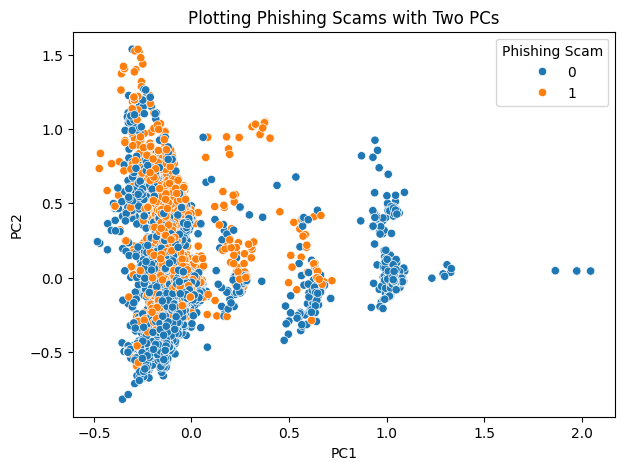

In [147]:
#Question 3
from sklearn.decomposition import PCA

pca_phish = PCA(n_components=2).fit(X_phish)
X_pca = pca_phish.transform(X_phish)

fig, ax = plt.subplots(figsize=(7, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_phish)
ax.set_title("Plotting Phishing Scams with Two PCs")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Phishing Scam")

According to the above plot, the vast majority of scam emails have a low value for the first principal component, as every datapoint with a PC1 score higher than ~0.8 is not asssociated with phishing. Conversely, the second principal component doesn't reveal any major patterns, with both types of emails present across the range of PC2

In [148]:
#Question 4

X_train, X_test, y_train, y_test = train_test_split(X_phish, y_phish, test_size=0.2, random_state=1)

pca_phish = PCA(n_components=2610).fit(X_train)
X_train_pca = pca_phish.transform(X_train)
X_test_pca = pca_phish.transform(X_test)

model = LinearRegression().fit(X_train_pca, y_train)

train_r2 = model.score(X_train_pca, y_train)
test_r2 = model.score(X_test_pca, y_test)

print(f"Training Model R-Squared: {train_r2:.3f}\nTest Model R-Squared: {test_r2:.3f}")

Training Model R-Squared: 0.768
Test Model R-Squared: 0.653


According to the above R-Squared values, which are identical to the training and test models from the earlier linear regression, the PCA model doesn't appear to perform any better than regular linear regression. This is likely due to the high number of components used for PCA, which is so close to the number of tokens in the dataset that barely any variation in the data is being reduced. 

Question 5: The advantage of using principal components on high-dimensionality data is to reduce the variation in the dataset by identifying linear combinations between dimensions (Principal Components), which increases predictive accuracy on average. Additionally, it allows high-dimensionality data to be visualized by reducing the dataset to two principal components and plotting each datapoint in accordance with them, revealing patterns in the data that would otherwise be impossible to find.  

### *Reflection on AI assistance
In your own words without generative AI.

Thanks to assistance from AI, I manged to make a series of improvements to my answers. These improvements are primarily associated with questions two and four, where I recognifgured each script so that the training and test data would be scored on a single model rather than seperate ones for each data type. From this, I also removed the table of test model coefficients since said model no longer existed.

However, the AI's suggestions were not without a slew of limitations. For example, many of the recommendations involved including information or performing operations that the questions did not ask for. Some of the suggestions, such as #3, went directly against the wording of the question it refered to when it asked for the absolute value operation to be removed. Additionally, a couple of the AI's recommendations failed to notice when the information it asked for was cited in an earlier solution.

Each suggestion was verified in a copy of this notebook when necessary.

As of now, I have no additional concerns, but the fact that AI refuses to cease including superfluous information in its answers despite being asked may be a sign that it's time to switch to a new AI model. 